# Collision-avoidance pass-through test: simulation

**The test.** The *runner* drone hovers at a fixed position. The *pursuer* drone is commanded along a straight
trajectory that passes **through** the runner's position. The pursuer passes if the envelopes never overlap, i.e. the normalized separation stays at or above 1.

**Envelopes.** Each drone has an axis-aligned ellipsoidal envelope with semi-axes $a = b = 0.0762$ m (3 in) and $c = 0.0381$ m (1.5 in). For two identical aligned
ellipsoids, the Minkowski sum is an ellipsoid with semi-axes $A = 2a$, $B = 2b$, $C = 2c$ (0.1524, 0.1524, 0.0762 m). With $\mathbf{r} = \mathbf{p}_i - \mathbf{p}_j$:

$$
q = \sqrt{\left(\frac{r_x}{A}\right)^2 + \left(\frac{r_y}{B}\right)^2 + \left(\frac{r_z}{C}\right)^2}
$$

The envelopes overlap when $q < 1$ and touch when $q = 1$. In the code this is `VOParams(R_i=a, R_j=a, z_stretch=c/a)`, so `z_stretch = 0.5`.
The safety `margin` is an extra buffer the controller defends *beyond* $q = 1$ (a placeholder, set it from your own data), so a controller that holds the margin reaches $q > 1$.

**Four modes**, matching how the subsystems were tested individually and then together:

| mode | what is active |
|---|---|
| `none` | trajectory tracking only (the baseline that should fail) |
| `vo` | velocity obstacle only |
| `envelope` | ellipsoidal keep-out filter only |
| `both` | velocity obstacle, then the ellipsoidal filter as a hard backstop |

The simulation uses the **same controller object** (`AvoidanceController`) as `flight_collision_avoidance.py`, driving a simple model of the drone's position loop.

In [17]:
import sys, os, json
from dataclasses import replace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

%matplotlib inline

sys.path.insert(0, os.getcwd())   # this notebook lives next to collision_avoidance.py
try:
    from ae483.collision_avoidance2 import (VOParams, TestConfig, PlantParams, simulate_pass_through,
                                     summarize_pass_through, normalized_separation,
                                     in_velocity_obstacle, min_q_from_mocap)
except ImportError:
    from ae483.collision_avoidance2 import (VOParams, TestConfig, PlantParams, simulate_pass_through,
                                           summarize_pass_through, normalized_separation,
                                           in_velocity_obstacle, min_q_from_mocap)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
MODES  = ['none', 'vo', 'envelope', 'both']
LABELS = {'none': 'No avoidance', 'vo': 'Velocity obstacle only', 'envelope': 'Envelope only',
          'both': 'VO + envelope'}
COLORS = {'none': 'tab:gray', 'vo': 'tab:blue', 'envelope': 'tab:green', 'both': 'tab:purple'}

## 1. Parameters

The envelope values come from the report. The margin, `vz_weight`, speed/acceleration limits and the geometry are **placeholders**: replace them with the numbers in your constraints table
and with the geometry of your lab. `PlantParams.wn` is a guess of how quickly the real drone follows a position setpoint; fit it to a
flight (commanded vs. measured position) before trusting the margins.

In [18]:
# Collision avoidance parameters (use the values from your parameter table)
P = VOParams(R_i=0.0762, R_j=0.0762,   # a = b of each drone's envelope (m)  [report: 3 in]
             z_stretch=0.5,            # c / a = 0.0381 / 0.0762                    [report: 1.5 in vertical]
             margin=0.02,              # extra buffer beyond q = 1 (m)  PLACEHOLDER
             vz_weight=10.0,           # >1: prefer dodging sideways over up/down (downwash); 1 = no preference
             tau=2.0,                  # VO prediction horizon (s)
             v_max=0.5,                # speed limit (m/s)
             a_max=1.25,                # acceleration limit (m/s^2)
             dt=0.05)                  # control period (s)

# Test settings
base_cfg = TestConfig(v_nom=0.5,                       # speed along the nominal path (m/s)
                      track_gain=1.5, max_lead=0.35,
                      inflate_for_tracking_error=True)

# Stand-in for the drone's position controller (a guess!)
plant = PlantParams(wn=5.0, zeta=1.0, pos_noise=0.0, vel_noise=0.0)

# Geometry (mocap frame, meters)
START  = (-1.5, 0.0, 0.5)   # where the pursuer's path begins
RUNNER = ( 0.0, 0.0, 0.5)   # where the runner hovers
OFFSET = ( 0.0, 0.0, 0.0)   # how far the path misses the runner's center (0 = straight through)

A, B, C = P.pair_axes
print(f'Pairwise envelope (q = 1): A = B = {A:.4f} m, C = {C:.4f} m')
print(f'Defended zone incl. margin: horizontal {P.R:.4f} m, vertical {P.z_stretch * P.R:.4f} m')

Pairwise envelope (q = 1): A = B = 0.1524 m, C = 0.0762 m
Defended zone incl. margin: horizontal 0.1724 m, vertical 0.0862 m


## 2. Run the four modes

In [19]:
def run_all(P, cfg, plant, offset=OFFSET, **cfg_over):
    return {m: simulate_pass_through(P, replace(cfg, mode=m, **cfg_over), plant, START, RUNNER, offset)
            for m in MODES}

def show_table(runs, P):
    print(f"{'mode':10s} {'q_min':>6s} {'at t (s)':>9s} {'q >= 1':>7s} {'finished path':>14s} {'% steps avoiding':>17s}")
    for m, L in runs.items():
        s = summarize_pass_through(L, P)
        print(f"{m:10s} {s['q_min']:6.2f} {s['t_q_min']:9.2f} {'PASS' if s['passed'] else 'FAIL':>7s} "
              f"{'yes' if s['finished_path'] else 'NO':>14s} {s['pct_avoiding']:17.0f}")

runs = run_all(P, base_cfg, plant)
show_table(runs, P)

mode        q_min  at t (s)  q >= 1  finished path  % steps avoiding
none         0.02      3.55    FAIL            yes                 0
vo           2.01      4.25    PASS            yes                37
envelope     1.13      8.95    PASS             NO                69
both         2.01      4.25    PASS            yes                37


**How to read the table.** `none` should fail (it flies through the runner). `vo` and `both` should pass and finish the path.
`envelope` alone passes $q \ge 1$ but, when the path goes exactly through the runner's center, it can stop at the surface of the ellipsoid and never get around:
the filter has no look-ahead and nothing pushes it sideways. A real path never passes *exactly* through the center, so try `OFFSET = (0, 0.03, 0)` above
and watch it finish.

## 3. Trajectories (top view and side view)

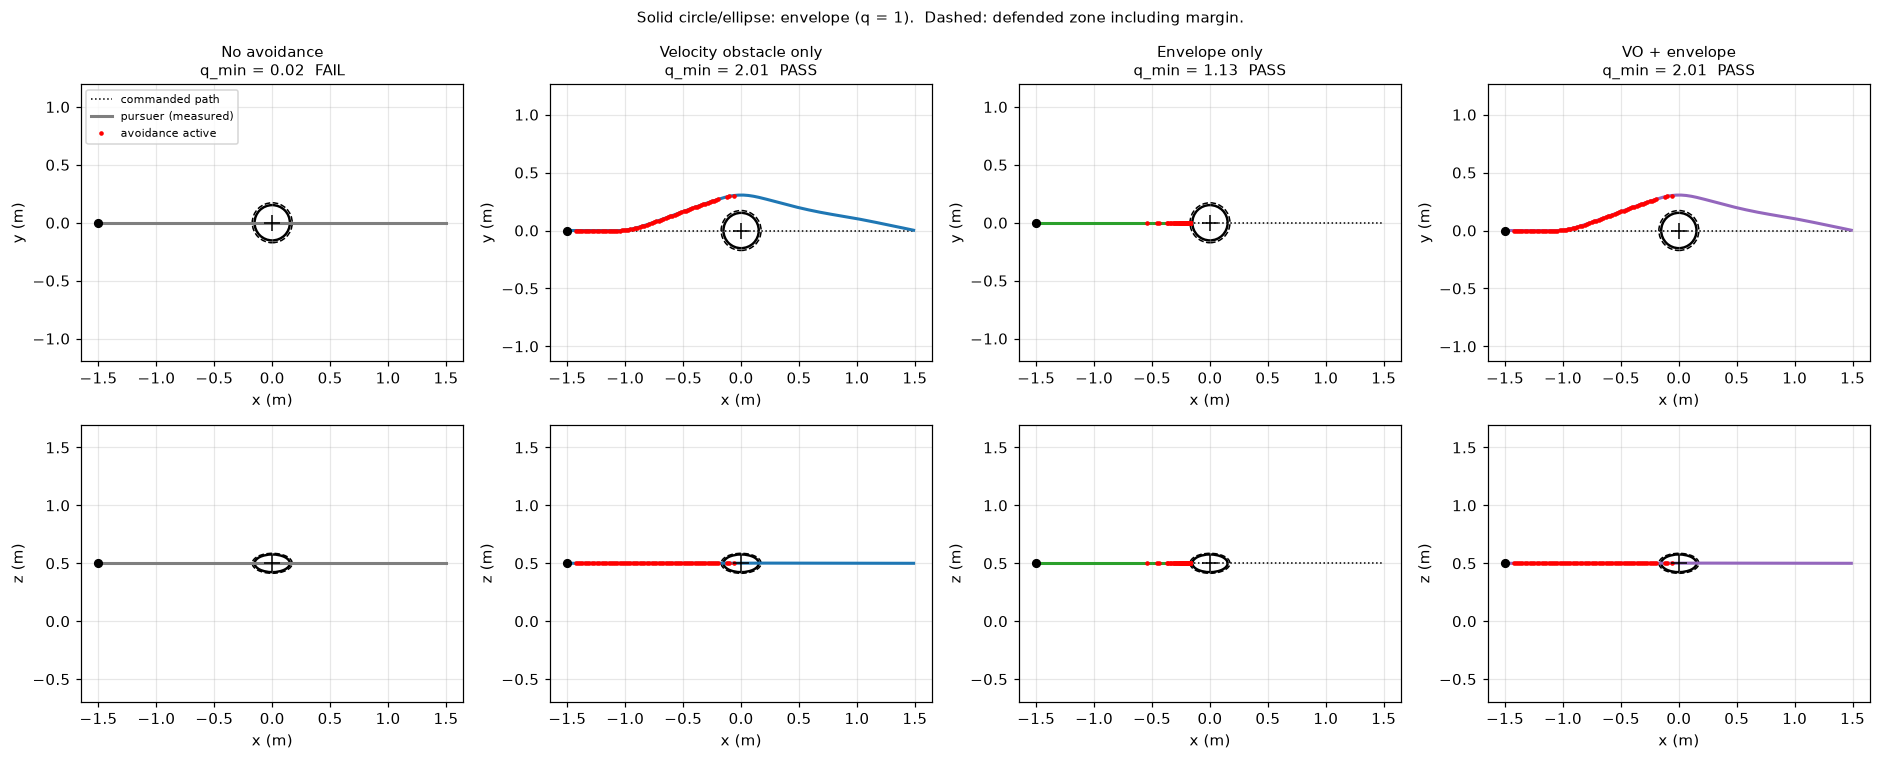

In [20]:
def draw_envelope(ax, axes_idx, c, P):
    a, b = axes_idx
    R_hard, R_zone = P.R_i + P.R_j, P.R
    kz = P.z_stretch if 2 in axes_idx else 1.0
    wide, high = (1.0, kz) if b == 2 else (1.0, 1.0)
    for R, ls, lw in [(R_hard, '-', 1.6), (R_zone, '--', 1.0)]:
        ax.add_patch(Ellipse((c[a], c[b]), 2 * R, 2 * R * high, fill=False, ec='k', ls=ls, lw=lw))

def plot_paths(runs, P):
    fig, axes = plt.subplots(2, len(runs), figsize=(4.3 * len(runs), 7), squeeze=False)
    for col, (m, L) in enumerate(runs.items()):
        s = summarize_pass_through(L, P)
        p, act = L['p_i'], L['status'] != 'free'
        for row, (a, b, ylab) in enumerate([(0, 1, 'y (m)'), (0, 2, 'z (m)')]):
            ax = axes[row, col]
            ax.plot([L['start'][a], L['end'][a]], [L['start'][b], L['end'][b]], 'k:', lw=1, label='commanded path')
            ax.plot(p[:, a], p[:, b], color=COLORS[m], lw=2, label='pursuer (measured)')
            ax.plot(p[act, a], p[act, b], '.', color='red', ms=4, label='avoidance active')
            draw_envelope(ax, (a, b), L['p_j'], P)
            ax.plot(L['p_j'][a], L['p_j'][b], 'k+', ms=10)
            ax.plot(L['start'][a], L['start'][b], 'ko', ms=5)
            ax.set_aspect('equal', adjustable='datalim')
            ax.set_xlabel('x (m)'); ax.set_ylabel(ylab)
            if row == 0:
                ax.set_title(f"{LABELS[m]}\nq_min = {s['q_min']:.2f}  {'PASS' if s['passed'] else 'FAIL'}", fontsize=10)
    axes[0, 0].legend(fontsize=7, loc='upper left')
    fig.suptitle('Solid circle/ellipse: envelope (q = 1).  Dashed: defended zone including margin.', fontsize=10)
    fig.tight_layout()
    plt.show()

plot_paths(runs, P)

## 4. Normalized separation $q$ over time

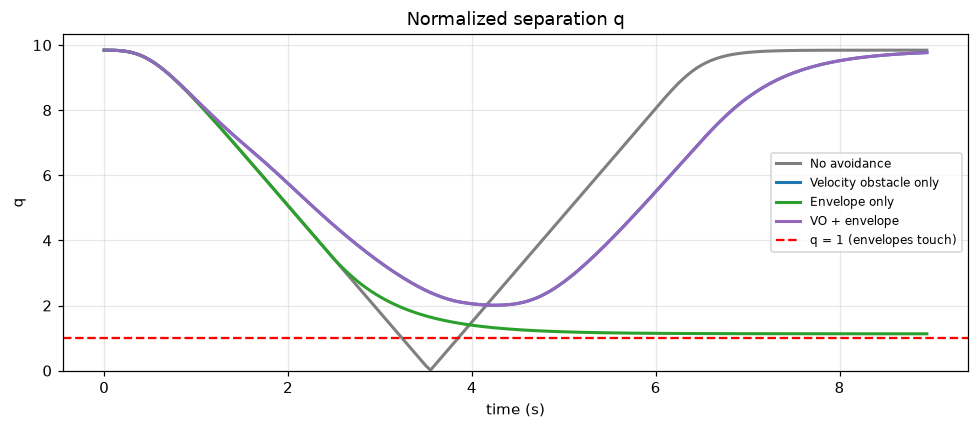

In [13]:
def plot_q(runs, title='Normalized separation q'):
    fig, ax = plt.subplots(figsize=(9, 4))
    for m, L in runs.items():
        ax.plot(L['t'], L['q'], color=COLORS[m], lw=2, label=LABELS[m])
    ax.axhline(1.0, color='red', ls='--', label='q = 1 (envelopes touch)')
    ax.set_ylim(bottom=0); ax.set_xlabel('time (s)'); ax.set_ylabel('q'); ax.set_title(title)
    ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

plot_q(runs)

## 5. 3D view

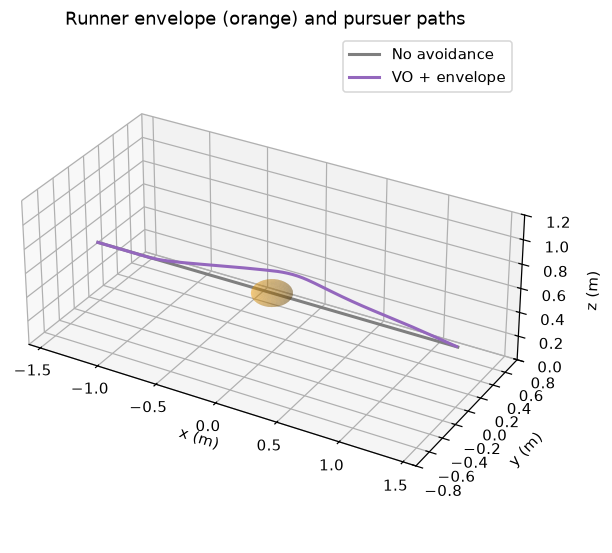

In [14]:
def ellipsoid_surface(c, a, cz, n=30):
    u, v = np.linspace(0, 2 * np.pi, n), np.linspace(0, np.pi, n)
    return (c[0] + a * np.outer(np.cos(u), np.sin(v)),
            c[1] + a * np.outer(np.sin(u), np.sin(v)),
            c[2] + cz * np.outer(np.ones_like(u), np.cos(v)))

def plot_3d(runs, P, modes=('none', 'both')):
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    c = runs[modes[0]]['p_j']
    ax.plot_surface(*ellipsoid_surface(c, P.R_i + P.R_j, P.z_stretch * (P.R_i + P.R_j)), alpha=0.3, color='orange')
    for m in modes:
        p = runs[m]['p_i']
        ax.plot(p[:, 0], p[:, 1], p[:, 2], color=COLORS[m], lw=2, label=LABELS[m])
    ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)'); ax.set_zlabel('z (m)')
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-0.8, 0.8); ax.set_zlim(0.0, 1.2)
    ax.set_box_aspect((3.2, 1.6, 1.2)); ax.legend(); ax.set_title('Runner envelope (orange) and pursuer paths')
    plt.show()

plot_3d(runs, P)

## 6. Why the VO picked this velocity (velocity space)

Red is the set of pursuer velocities that would hit the runner within the horizon $\tau$ (the velocity obstacle, here for the *inflated* zone the controller actually uses).
The small blue circle is where the pursuer can get to in one step ($a_{max}\,\Delta t$), the dashed circle is the speed limit. Two slices of the 3D velocity space are shown.

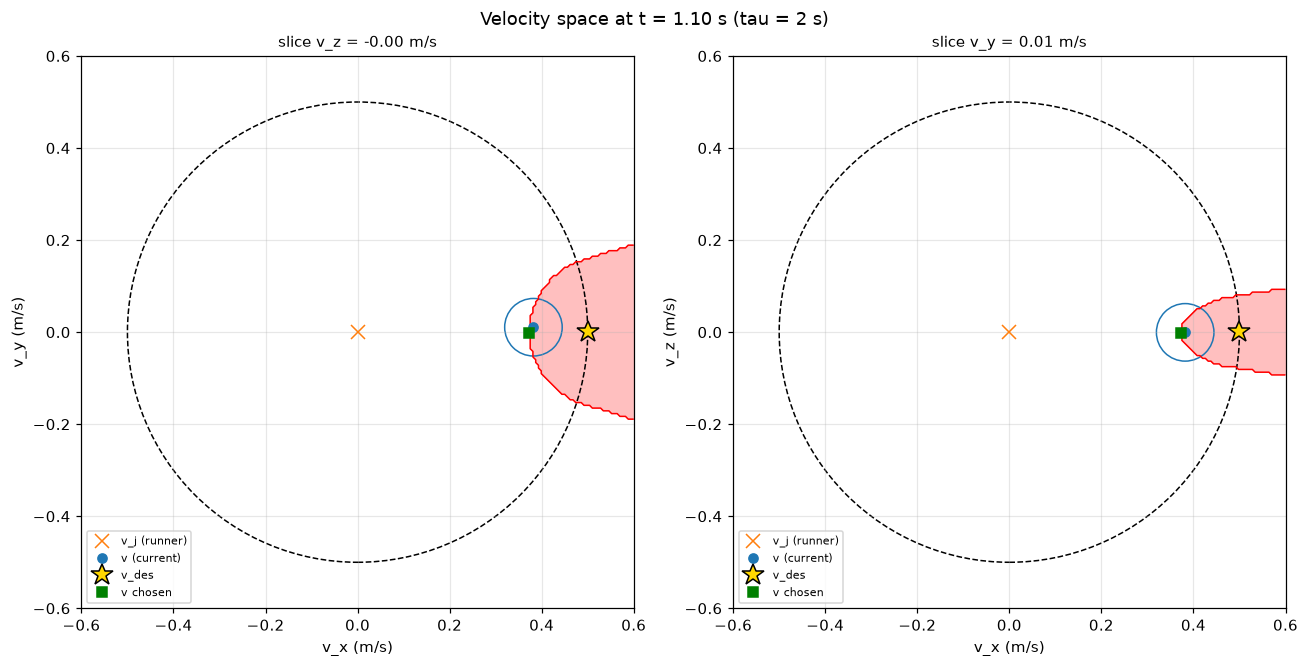

In [15]:
def vo_snapshot(L, P, cfg, k=None):
    idx = np.flatnonzero(L['status'] == 'avoiding')
    if k is None:
        k = min((idx[0] + 10) if len(idx) else 1, len(L['t']) - 1)
    p_plan, v_prev = L['sp'][k - 1], L['v_cmd'][k - 1]
    lead = np.linalg.norm(L['sp'][k - 1] - L['p_i'][k])
    P_eff = replace(P, margin=P.margin + (min(lead, cfg.max_lead) if cfg.inflate_for_tracking_error else 0.0))
    v_j = np.zeros(3)
    lim = P.v_max * 1.2
    u = np.linspace(-lim, lim, 201)
    U, W = np.meshgrid(u, u)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
        c = 3 - a - b
        V = np.zeros((U.size, 3)); V[:, a], V[:, b], V[:, c] = U.ravel(), W.ravel(), v_prev[c]
        mask = in_velocity_obstacle(V, p_plan, L['p_j'], v_j, P_eff).reshape(U.shape).astype(float)
        ax.contourf(U, W, mask, levels=[0.5, 1.5], colors=['red'], alpha=0.25)
        ax.contour(U, W, mask, levels=[0.5], colors=['red'], linewidths=1)
        ax.add_patch(Circle((0, 0), P.v_max, fill=False, ec='k', ls='--'))
        ax.add_patch(Circle((v_prev[a], v_prev[b]), P.a_max * P.dt, fill=False, ec='C0'))
        ax.plot(v_j[a], v_j[b], 'x', color='C1', ms=9, label='v_j (runner)')
        ax.plot(v_prev[a], v_prev[b], 'o', color='C0', label='v (current)')
        ax.plot(L['v_des'][k][a], L['v_des'][k][b], '*', color='gold', mec='k', ms=15, label='v_des')
        ax.plot(L['v_cmd'][k][a], L['v_cmd'][k][b], 's', color='green', label='v chosen')
        n = 'xyz'
        ax.set_xlabel(f'v_{n[a]} (m/s)'); ax.set_ylabel(f'v_{n[b]} (m/s)')
        ax.set_title(f'slice v_{n[c]} = {v_prev[c]:.2f} m/s', fontsize=10)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal'); ax.legend(fontsize=7, loc='lower left')
    fig.suptitle(f"Velocity space at t = {L['t'][k]:.2f} s (tau = {P.tau:g} s)")
    fig.tight_layout(); plt.show()

vo_snapshot(runs['vo'], P, replace(base_cfg, mode='vo'))

## 7. Animation

In [16]:
matplotlib.rcParams['animation.embed_limit'] = 60   # MB

def animate_run(L, P, step=4):
    frames = np.arange(0, len(L['t']), step)
    fig, (axa, axb, axc) = plt.subplots(1, 3, figsize=(13, 3.8), dpi=60)
    for ax, (a, b), ylab in [(axa, (0, 1), 'y (m)'), (axb, (0, 2), 'z (m)')]:
        ax.plot([L['start'][a], L['end'][a]], [L['start'][b], L['end'][b]], 'k:', lw=1)
        draw_envelope(ax, (a, b), L['p_j'], P)
        ax.plot(L['p_j'][a], L['p_j'][b], 'k+', ms=10)
        ax.set_xlim(-1.7, 1.7)
        ax.set_xlabel('x (m)'); ax.set_ylabel(ylab)
    axa.set_ylim(-0.9, 0.9); axb.set_ylim(0.0, 1.3)
    axa.set_aspect('equal', adjustable='box'); axb.set_aspect('equal', adjustable='box')
    axa.set_title('Top view'); axb.set_title('Side view')
    trail_a, = axa.plot([], [], color=COLORS[L['mode']], lw=2); dot_a, = axa.plot([], [], 'o', color=COLORS[L['mode']])
    trail_b, = axb.plot([], [], color=COLORS[L['mode']], lw=2); dot_b, = axb.plot([], [], 'o', color=COLORS[L['mode']])
    sp_a, = axa.plot([], [], 'x', color='red'); sp_b, = axb.plot([], [], 'x', color='red')
    axc.plot(L['t'], L['q'], color=COLORS[L['mode']], lw=2)
    axc.axhline(1, color='red', ls='--'); axc.set_ylim(0, max(2.5, 1.1 * L['q'].max()))
    axc.set_xlabel('time (s)'); axc.set_ylabel('q'); axc.set_title(f"q (mode: {LABELS[L['mode']]})")
    cursor = axc.axvline(0, color='k', lw=1)
    def update(f):
        k = frames[f]; p = L['p_i']
        trail_a.set_data(p[:k + 1, 0], p[:k + 1, 1]); dot_a.set_data([p[k, 0]], [p[k, 1]]); sp_a.set_data([L['sp'][k, 0]], [L['sp'][k, 1]])
        trail_b.set_data(p[:k + 1, 0], p[:k + 1, 2]); dot_b.set_data([p[k, 0]], [p[k, 2]]); sp_b.set_data([L['sp'][k, 0]], [L['sp'][k, 2]])
        cursor.set_xdata([L['t'][k], L['t'][k]])
        return trail_a, dot_a, sp_a, trail_b, dot_b, sp_b, cursor
    fig.tight_layout()
    anim = FuncAnimation(fig, update, frames=len(frames), interval=100, blit=False)
    plt.close(fig)
    return anim

HTML(animate_run(runs['both'], P).to_jshtml())   # red x = setpoint sent to the drone

## 8. Stress test: when the VO alone is not enough

If the horizon is short and the drone has little acceleration authority, the VO is cornered (every reachable velocity collides within $\tau$) and cannot
avoid in time. This is the situation the ellipsoidal filter is for: it keeps the planned setpoint out of the zone regardless of look-ahead.

(Ignore the *finished path* column here: with $a_{max} = 0.5$ m/s² the pursuer cannot keep up with a 1 m/s time-based reference, so no mode finishes.)

mode        q_min  at t (s)  q >= 1  finished path  % steps avoiding
none         0.07      3.75    FAIL             NO                 0
vo           0.44      3.10    FAIL             NO                24
envelope     1.15      5.95    PASS             NO                43
both         1.61      3.90    PASS             NO                27


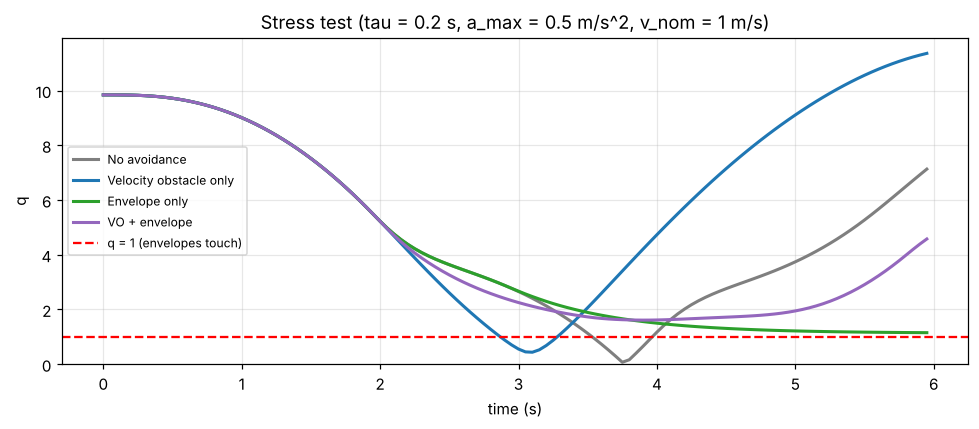

In [9]:
P_stress = replace(P, tau=0.2, a_max=0.5)
runs_stress = run_all(P_stress, base_cfg, plant, v_nom=1.0)
show_table(runs_stress, P_stress)
plot_q(runs_stress, title='Stress test (tau = 0.2 s, a_max = 0.5 m/s^2, v_nom = 1 m/s)')

## 9. Sensitivity: why the controller inflates its margin by the tracking error

A real drone follows its setpoint with a lag and cuts corners, so it is *not* where the plan says it is. The controller therefore adds $\lVert \text{setpoint} - \text{drone} \rVert$ to the margin
(`inflate_for_tracking_error`). The plot sweeps the position-loop bandwidth `wn` (low = sluggish drone). Without the inflation and with no margin,
the **measured** $q$ drops below 1 even though the plan respected the zone.

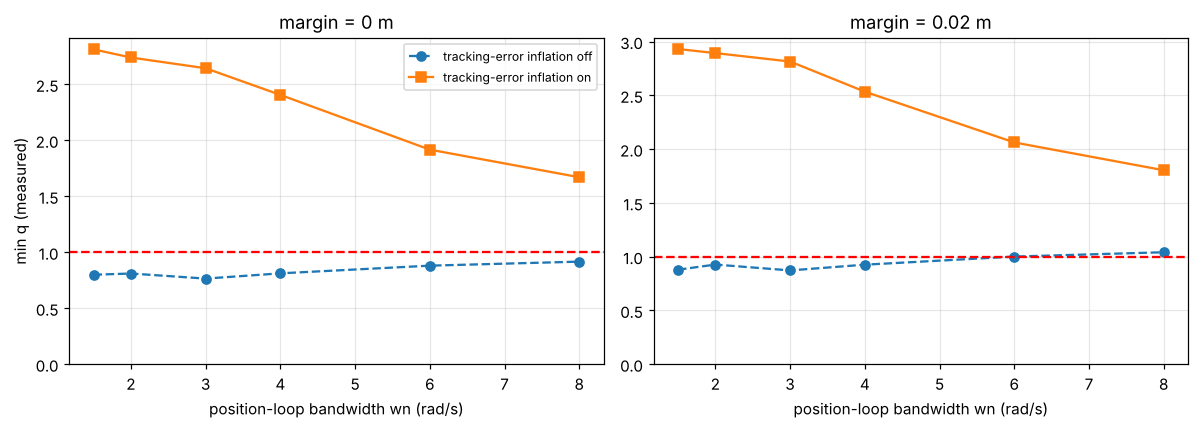

In [10]:
wns = [1.5, 2, 3, 4, 6, 8]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, margin in zip(axes, [0.0, 0.02]):
    for infl, style in [(False, 'o--'), (True, 's-')]:
        qs = []
        for wn in wns:
            L = simulate_pass_through(replace(P, margin=margin), replace(base_cfg, mode='both', inflate_for_tracking_error=infl),
                                      replace(plant, wn=wn), START, RUNNER, OFFSET)
            qs.append(summarize_pass_through(L, P)['q_min'])
        ax.plot(wns, qs, style, label=f'tracking-error inflation {"on" if infl else "off"}')
    ax.axhline(1, color='red', ls='--'); ax.set_ylim(bottom=0)
    ax.set_xlabel('position-loop bandwidth wn (rad/s)'); ax.set_title(f'margin = {margin:g} m')
axes[0].set_ylabel('min q (measured)'); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 10. Explore interactively

Needs `ipywidgets` (`pip install ipywidgets`). Move the sliders to see how the mode, envelope shape, margin, vertical-evasion weight, horizon, acceleration limit, speed, drone bandwidth, and path offset change $q$.

In [11]:
def explore(mode='both', z_stretch=0.5, margin=0.02, vz_weight=10.0, tau=2.0, a_max=2.0, v_nom=0.5, wn=5.0, offset_y=0.0):
    P_ = replace(P, z_stretch=z_stretch, margin=margin, vz_weight=vz_weight, tau=tau, a_max=a_max)
    L = simulate_pass_through(P_, replace(base_cfg, mode=mode, v_nom=v_nom), replace(plant, wn=wn), START, RUNNER, (0.0, offset_y, 0.0))
    s = summarize_pass_through(L, P_)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (a, b), ylab in [(axes[0], (0, 1), 'y (m)'), (axes[1], (0, 2), 'z (m)')]:
        ax.plot([L['start'][a], L['end'][a]], [L['start'][b], L['end'][b]], 'k:', lw=1)
        ax.plot(L['p_i'][:, a], L['p_i'][:, b], color=COLORS[mode], lw=2)
        act = L['status'] != 'free'
        ax.plot(L['p_i'][act, a], L['p_i'][act, b], '.', color='red', ms=4)
        draw_envelope(ax, (a, b), L['p_j'], P_)
        ax.set_aspect('equal', adjustable='datalim'); ax.set_xlabel('x (m)'); ax.set_ylabel(ylab)
    axes[2].plot(L['t'], L['q'], color=COLORS[mode], lw=2); axes[2].axhline(1, color='red', ls='--')
    axes[2].set_ylim(bottom=0); axes[2].set_xlabel('time (s)'); axes[2].set_ylabel('q')
    axes[2].set_title(f"min q = {s['q_min']:.2f}  {'PASS' if s['passed'] else 'FAIL'}  |  finished path: {'yes' if s['finished_path'] else 'no'}")
    fig.tight_layout(); plt.show()

try:
    import ipywidgets as w
    w.interact(explore, mode=MODES,
               z_stretch=w.FloatSlider(min=0.25, max=2.0, step=0.05, value=0.5),
               margin=w.FloatSlider(min=0.0, max=0.1, step=0.005, value=0.02),
               vz_weight=w.FloatSlider(min=1.0, max=50.0, step=1.0, value=10.0),
               tau=w.FloatSlider(min=0.1, max=3.0, step=0.1, value=2.0),
               a_max=w.FloatSlider(min=0.3, max=4.0, step=0.1, value=2.0),
               v_nom=w.FloatSlider(min=0.2, max=1.0, step=0.05, value=0.5),
               wn=w.FloatSlider(min=1.5, max=10.0, step=0.5, value=5.0),
               offset_y=w.FloatSlider(min=-0.3, max=0.3, step=0.01, value=0.0));
except ImportError:
    print('ipywidgets is not installed (pip install ipywidgets). Calling explore() once with the defaults instead:')
    explore()

interactive(children=(Dropdown(description='mode', index=3, options=('none', 'vo', 'envelope', 'both'), value=…

## 11. Analyze a real flight

`flight_collision_avoidance.py` saves a JSON file for each flight. Point `FLIGHT_FILE` at the **pursuer's** file to compute $q$ from the logged mocap data
(100 Hz) and get the minimum value for the trial.

In [12]:
FLIGHT_FILE = 'pursuer_test_1.json'   # <- change me

if not os.path.exists(FLIGHT_FILE):
    print(f'{FLIGHT_FILE} not found yet. Fly the test, then set FLIGHT_FILE to the data file of the pursuer flight.')
else:
    with open(FLIGHT_FILE) as f:
        data = json.load(f)
    t_info = data['test']
    P_f = VOParams(**t_info['params'])
    me, other = t_info['me'], t_info['other']
    q_min, q = min_q_from_mocap(data['bodies'][me], data['bodies'][other], P_f)
    t = np.array(data['bodies'][me]['time']); t = t - t[0]
    n = min(len(t), len(q))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    xi, yi, zi = (np.array(data['bodies'][me][k]) for k in 'xyz')
    xj, yj, zj = (np.array(data['bodies'][other][k]) for k in 'xyz')
    axes[0].plot(xi, yi, label=f'pursuer ({me})'); axes[0].plot(xj, yj, label=f'runner ({other})')
    axes[0].set_aspect('equal', adjustable='datalim'); axes[0].set_xlabel('x (m)'); axes[0].set_ylabel('y (m)'); axes[0].legend(fontsize=8)
    axes[1].plot(xi, zi); axes[1].plot(xj, zj); axes[1].set_xlabel('x (m)'); axes[1].set_ylabel('z (m)')
    axes[2].plot(t[:n], q[:n]); axes[2].axhline(1, color='red', ls='--'); axes[2].set_ylim(bottom=0)
    axes[2].set_xlabel('time (s)'); axes[2].set_ylabel('q')
    axes[2].set_title(f"min q = {q_min:.2f}  {'PASS' if q_min >= 1 else 'FAIL'}  (mode: {t_info['config']['mode']})")
    fig.tight_layout(); plt.show()
    print(f'Minimum normalized separation in this trial: {q_min:.3f}')

pursuer_test_1.json not found yet. Fly the test, then set FLIGHT_FILE to the data file of the pursuer flight.
